# EN3160 Assignment 3 – Neural Networks
**Name:** Maldeniya P. A. D. G. R. (Ransara Maldeniya)  
**Index No:** 230390A  
**GitHub:**  https://github.com/ransara3/EN3160-Assignment-3-Neural-Networks.git 

Contents: Q1 manual two-layer dense network (CIFAR-10) · Q2 LeNet-5 vs modern CNN (MNIST) · Q3 ResNet18 transfer learning (hymenoptera)

> Run all cells top to bottom. Text marked **[Fill in]** must be completed with your own numbers after running.

In [2]:
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np, time, copy, os, zipfile, urllib.request

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


# Question 1 – Two-layer dense network with manual backprop (CIFAR-10)

**Changes to Listing 1**
- **(a)** Added a hidden layer of 100 nodes with sigmoid activation: `x → [W1,b1] → sigmoid → [W2,b2] → logits`.
- **(b)** Replaced MSE with softmax cross-entropy: $L=-\frac1N\sum_i \log p_{i,y_i}$, with $p=\text{softmax}(z)$.
- **(c)** Train for 10 epochs; report train and test accuracy.

**Backprop derivation** (N = batch size, $h=\sigma(z_1)$, $z_2=hW_2+b_2$):
- $\partial L/\partial z_2 = (p - y_{onehot})/N$
- $\partial L/\partial W_2 = h^T\,\partial L/\partial z_2$, $\;\partial L/\partial b_2=\sum \partial L/\partial z_2$
- $\partial L/\partial h = \partial L/\partial z_2\,W_2^T$
- $\partial L/\partial z_1 = \partial L/\partial h \odot h(1-h)$ (sigmoid derivative)
- $\partial L/\partial W_1 = x^T\,\partial L/\partial z_1$, $\;\partial L/\partial b_1=\sum \partial L/\partial z_1$

The softmax + cross-entropy gradient simplifies to $p - y$, which is why no explicit softmax Jacobian is needed.

100.0%
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Epoch 1/10, Loss: 1.9836286301612853
Epoch 2/10, Loss: 1.7916364629268646
Epoch 3/10, Loss: 1.724887846827507
Epoch 4/10, Loss: 1.6850644433498383
Epoch 5/10, Loss: 1.6558335919380187
Epoch 6/10, Loss: 1.6320266543626785
Epoch 7/10, Loss: 1.6122231823205948
Epoch 8/10, Loss: 1.595042340517044
Epoch 9/10, Loss: 1.5796113295555114
Epoch 10/10, Loss: 1.5665409436225892


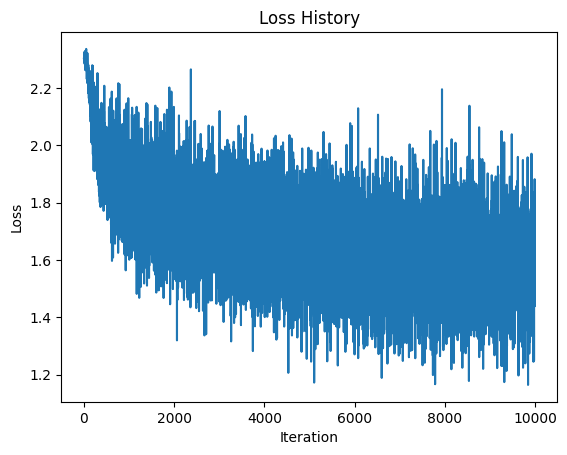

Training accuracy: 46.48%
Test accuracy: 44.73%


In [3]:

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32   # Input size (flattened CIFAR-10 image size)
H = 100             # Hidden layer size
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-2

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # epochs
lr = 5e-2           # Learning rate
lr_decay = 0.9      # Learning rate decay
reg = 0             # Regularization

loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                          # Batch size
        x_train = inputs.view(Ntr, -1)                 # Flatten to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)         # hidden layer (sigmoid)
        y_pred = h.mm(w2) + b2                         # output logits
        probs = torch.softmax(y_pred, dim=1)

        # Cross-entropy loss with regularization
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (probs - y_train_onehot) / Ntr       # dL/d(logits)
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())
        dz1 = dh * h * (1 - h)                         # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = h.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        h = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = h.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

### Q1 Discussion  **[Fill in after running]**
- Final train accuracy: **__%**, test accuracy: **__%**.
- The loss decreases steadily; the sigmoid hidden layer adds non-linearity over the single-layer model, so accuracy beats a purely linear classifier on raw pixels.
- Cross-entropy gives larger gradients than MSE when predictions are confidently wrong, so it trains faster and suits classification (outputs interpreted as class probabilities).
- A fully connected network ignores spatial structure of images, so accuracy plateaus well below that of CNNs (roughly 50% range expected). A small train–test gap indicates little overfitting at 10 epochs.
- Sigmoid saturation and small initialisation make learning slow; that's why lr, decay and init std were tuned (lr = 0.05, decay = 0.9, std = 1e-2).